## LSTM Station Demand Forecast

Deep 3-layer LSTM trained on per-station daily ride counts.
Sliding-window sequences of length `SEQ_LEN` days → predict next-day rides.
Same feature engineering and train/val/test split as notebook 06.

## 1. Setup & Data Prep

In [234]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output
from dotenv import load_dotenv
from sklearn.preprocessing import MinMaxScaler

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')

station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
station = station[station['start_station_name'] != 'Outside of Dock']

weather      = s3.read_processed('weather/historical')
weather['date'] = pd.to_datetime(weather['date'])
weather_fcst = s3.read_processed('weather/forecast')
weather_fcst['date'] = pd.to_datetime(weather_fcst['date'])

print('Station:', station.shape)
print('Weather (hist):', weather.shape)
print('Weather (fcst):', weather_fcst.shape)

Station: (1402616, 7)
Weather (hist): (2251, 5)
Weather (fcst): (2251, 5)


In [235]:
# Filter to stations active on >95% of days
n_days = station['date'].nunique()
min_active_days = int(0.99 * n_days)
active_stations = (
    station.groupby('start_station_name')['date']
    .nunique()
    .loc[lambda s: s > min_active_days]
    .index
)
df = station[station['start_station_name'].isin(active_stations)].copy()
print(f'Stations kept (>{min_active_days}/{n_days} days): {len(active_stations)}')

Stations kept (>2226/2249 days): 153


## 2. Feature Engineering

In [236]:
# Merge weather
df = df.merge(
    weather[["date", "temp_min_c", "rain_sum_mm", "snowfall_sum_cm", "wind_speed_max_kmh"]],
    on="date", how="left"
)
df = df.sort_values(["start_station_name", "date"]).reset_index(drop=True)

# Calendar
df["month"]        = df["date"].dt.month
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
df["weekday"]      = df["date"].dt.weekday
df["is_weekend"]   = df["weekday"].isin([5, 6]).astype(int)

DOW_COLS = [f"dow_{d}" for d in range(7)]
for d in range(7):
    df[f"dow_{d}"] = (df["weekday"] == d).astype(int)

# Lags beyond the 7-day window
grp = df.groupby("start_station_name")["total_rides"]
df["y_lag30"]  = grp.shift(30)
df["y_lag60"]  = grp.shift(60)
df["y_lag90"]  = grp.shift(90)
df["y_lag365"] = grp.shift(365)

# Rolling stats
df["rolling_std_7"]  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=2).std().fillna(0))
df["rolling_max_7"]  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=1).max())
df["rolling_min_7"]  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=1).min())
df["rolling_avg_30"] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=1).mean())
df["rolling_std_30"] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=2).std().fillna(0))
df["rolling_max_30"] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=1).max())
df["rolling_min_30"] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=1).min())

# Long-range proportion features
total_safe = df["total_rides"].replace(0, np.nan)
df["ebike_prop"]  = df["ebike_rides"]  / total_safe
df["member_prop"] = df["member_rides"] / total_safe
for col in ["ebike_prop", "member_prop"]:
    df[f"{col}_roll365_lag1"] = (
        df.groupby("start_station_name")[col]
        .transform(lambda x: x.shift(1).rolling(365, min_periods=30).mean())
    )

# Station dummies
station_dummies = pd.get_dummies(df["start_station_name"], prefix="stn", drop_first=False)
df = pd.concat([df, station_dummies], axis=1)
STATION_COLS = station_dummies.columns.tolist()

df = df.dropna(subset=["temp_min_c", "y_lag90", "y_lag365", "ebike_prop_roll365_lag1"])
print(f"Rows: {len(df):,}  |  Stations: {len(STATION_COLS)}")
df.head()

Rows: 286,532  |  Stations: 153


,date,start_station_name,start_station_id,total_rides,ebike_rides,member_rides,casual_rides,temp_min_c,rain_sum_mm,snowfall_sum_cm,...,stn_Wells St & Elm St,stn_Wells St & Evergreen Ave,stn_Wells St & Hubbard St,stn_Wells St & Huron St,stn_Wells St & Polk St,stn_Wells St & Walton St,stn_Western Ave & Winnebago Ave,stn_Wilton Ave & Belmont Ave,stn_Wilton Ave & Diversey Pkwy,stn_Wolcott Ave & Polk St
365,2021-01-04,Aberdeen St & Jackson Blvd,13157,14,3,14,0,-4.4,0.0,0.07,...,False,False,False,False,False,False,False,False,False,False
366,2021-01-05,Aberdeen St & Jackson Blvd,13157,15,5,14,1,-4.4,0.0,0.00,...,False,False,False,False,False,False,False,False,False,False
367,2021-01-06,Aberdeen St & Jackson Blvd,13157,11,3,11,0,-2.5,0.0,0.00,...,False,False,False,False,False,False,False,False,False,False
368,2021-01-07,Aberdeen St & Jackson Blvd,13157,14,2,14,0,-0.2,0.0,0.00,...,False,False,False,False,False,False,False,False,False,False
369,2021-01-08,Aberdeen St & Jackson Blvd,13157,18,3,18,0,-0.2,0.0,0.00,...,False,False,False,False,False,False,False,False,False,False


## 3. Train / Val / Test Split

In [237]:
max_date   = df['date'].max()
test_start = max_date - pd.DateOffset(years=1) + pd.Timedelta(days=1)
val_start  = max_date - pd.DateOffset(years=2) + pd.Timedelta(days=1)

train = df[df['date'] <  val_start].copy()
val   = df[(df['date'] >= val_start) & (df['date'] < test_start)].copy()
test  = df[df['date'] >= test_start].copy()

print(f'Train: {train["date"].min().date()} -> {train["date"].max().date()}  ({len(train):,} rows)')
print(f'Val:   {val["date"].min().date()}   -> {val["date"].max().date()}    ({len(val):,} rows)')
print(f'Test:  {test["date"].min().date()}  -> {test["date"].max().date()}   ({len(test):,} rows)')

# Swap real weather for forecast weather in test
WEATHER_COLS = ['temp_min_c', 'rain_sum_mm', 'snowfall_sum_cm', 'wind_speed_max_kmh']
test = test.drop(columns=WEATHER_COLS).merge(
    weather_fcst[['date'] + WEATHER_COLS], on='date', how='left'
)

Train: 2021-01-02 -> 2024-02-28  (175,137 rows)
Val:   2024-02-29   -> 2025-02-28    (55,863 rows)
Test:  2025-03-01  -> 2026-02-28   (55,532 rows)


## 4. Sequence Dataset

In [238]:
WEATHER_COLS = ["temp_min_c", "rain_sum_mm", "snowfall_sum_cm", "wind_speed_max_kmh"]
LAG_COLS     = ["y_lag30", "y_lag60", "y_lag90", "y_lag365"]
ROLL_COLS    = ["rolling_std_7", "rolling_max_7", "rolling_min_7", "rolling_avg_30", "rolling_std_30", "rolling_max_30", "rolling_min_30"]
PROP_COLS    = ["ebike_prop_roll365_lag1", "member_prop_roll365_lag1"]

SEQ_COLS = (
    ["total_rides", "month", "week_of_year", "is_weekend"]
    + DOW_COLS
    + WEATHER_COLS
    + LAG_COLS
    + ROLL_COLS
    + PROP_COLS
)
TARGET  = "total_rides"
SEQ_LEN = 14

# Feature scaler (MinMax on SEQ_COLS)
scaler = MinMaxScaler()
scaler.fit(train[SEQ_COLS].fillna(0))

# Target scaler for inverse-transforming predictions to raw counts
target_scaler = MinMaxScaler()
target_scaler.fit(train[[TARGET]])

def scale(split):
    out = split.copy()
    out[SEQ_COLS] = scaler.transform(split[SEQ_COLS].fillna(0))
    return out

train_s = scale(train)
val_s   = scale(val)
test_s  = scale(test)

print(f"SEQ_COLS ({len(SEQ_COLS)}): {SEQ_COLS}")
print(f"STATION_COLS ({len(STATION_COLS)}) -> compressed by station_encoder")
print(f"SEQ_LEN: {SEQ_LEN}  (lag1/2/7 + rolling_7 covered by window, excluded)")

SEQ_COLS (28): ['total_rides', 'month', 'week_of_year', 'is_weekend', 'dow_0', 'dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6', 'temp_min_c', 'rain_sum_mm', 'snowfall_sum_cm', 'wind_speed_max_kmh', 'y_lag30', 'y_lag60', 'y_lag90', 'y_lag365', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'rolling_avg_30', 'rolling_std_30', 'rolling_max_30', 'rolling_min_30', 'ebike_prop_roll365_lag1', 'member_prop_roll365_lag1']
STATION_COLS (153) -> compressed by station_encoder
SEQ_LEN: 14  (lag1/2/7 + rolling_7 covered by window, excluded)


In [239]:
class StationSeqDataset(Dataset):
    """
    Returns:
      x_seq     — (seq_len, n_seq_cols)   LSTM input window
      x_stn     — (n_stations,)           station one-hot (static per sequence)
      w_target  — (n_weather,)            target-day weather
      y_rides   — scalar raw ride count
      y_open    — binary open flag
    """
    def __init__(self, df, seq_cols, station_cols, weather_cols, target_col, seq_len):
        self.seqs, self.stns, self.w_targets, self.targets, self.is_open = [], [], [], [], []
        for _, grp in df.groupby("start_station_name", sort=False):
            grp = grp.sort_values("date")
            X   = grp[seq_cols].values.astype("float32")      # (T, F)
            S   = grp[station_cols].values.astype("float32")  # (T, n_stn) — constant rows
            W   = grp[weather_cols].values.astype("float32")  # (T, 4)
            y   = grp[target_col].values.astype("float32")    # (T,)
            for i in range(seq_len, len(grp)):
                self.seqs.append(X[i - seq_len : i])
                self.stns.append(S[i])       # same for all i in this station
                self.w_targets.append(W[i])
                self.targets.append(y[i])
                self.is_open.append(float(y[i] > 0))
        self.seqs      = np.stack(self.seqs)
        self.stns      = np.stack(self.stns)
        self.w_targets = np.stack(self.w_targets)
        self.targets   = np.array(self.targets,  dtype="float32")
        self.is_open   = np.array(self.is_open,  dtype="float32")

    def __len__(self): return len(self.targets)
    def __getitem__(self, i):
        return (torch.tensor(self.seqs[i]),
                torch.tensor(self.stns[i]),
                torch.tensor(self.w_targets[i]),
                torch.tensor(self.targets[i]),
                torch.tensor(self.is_open[i]))


train_ds = StationSeqDataset(train_s, SEQ_COLS, STATION_COLS, WEATHER_COLS, TARGET, SEQ_LEN)
val_ds   = StationSeqDataset(val_s,   SEQ_COLS, STATION_COLS, WEATHER_COLS, TARGET, SEQ_LEN)
test_ds  = StationSeqDataset(test_s,  SEQ_COLS, STATION_COLS, WEATHER_COLS, TARGET, SEQ_LEN)

train_loader = DataLoader(train_ds, batch_size=512, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=512, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=512, shuffle=False, num_workers=0)

print(f"Train: {len(train_ds):,}  Val: {len(val_ds):,}  Test: {len(test_ds):,}")
print(f"Seq shape: {train_ds.seqs[0].shape}  Stn shape: {train_ds.stns[0].shape}")

Train: 172,995  Val: 53,721  Test: 53,390
Seq shape: (14, 28)  Stn shape: (153,)


## 5. Model Architecture

In [240]:
N_SEQ      = len(SEQ_COLS)
N_STATIONS = len(STATION_COLS)
N_WEATHER  = len(WEATHER_COLS)
HIDDEN     = 128
NUM_LAYERS = 3
STN_DIM    = 16   # compressed station embedding size


class DeepLSTMForecaster(nn.Module):
    def __init__(self, n_seq, n_stations, hidden, num_layers, n_weather, stn_dim):
        super().__init__()
        # Compress station one-hot → dense embedding
        self.station_encoder = nn.Sequential(
            nn.Linear(n_stations, 64),
            nn.ReLU(),
            nn.Linear(64, stn_dim),
            nn.ReLU(),
        )
        self.lstm = nn.LSTM(
            input_size  = n_seq + stn_dim,   # seq features + station embedding
            hidden_size = hidden,
            num_layers  = num_layers,
            batch_first = True,
        )
        self.norm = nn.LayerNorm(hidden)
        head_in = hidden + n_weather
        self.ride_head = nn.Sequential(
            nn.Linear(head_in,     hidden),
            nn.ReLU(),
            nn.Linear(hidden,      hidden // 2),
            nn.ReLU(),
            nn.Linear(hidden // 2, 1),
            nn.ReLU(),
        )
        self.open_head = nn.Sequential(
            nn.Linear(head_in,     hidden // 2),
            nn.ReLU(),
            nn.Linear(hidden // 2, hidden // 4),
            nn.ReLU(),
            nn.Linear(hidden // 4, 1),
            nn.Sigmoid(),
        )

    def forward(self, x_seq, x_stn, w_target):
        # x_seq:    (B, seq_len, n_seq)
        # x_stn:    (B, n_stations)
        # w_target: (B, n_weather)
        s_emb = self.station_encoder(x_stn)              # (B, stn_dim)
        s_emb = s_emb.unsqueeze(1).expand(-1, x_seq.shape[1], -1)  # (B, seq_len, stn_dim)
        x_in  = torch.cat([x_seq, s_emb], dim=-1)        # (B, seq_len, n_seq+stn_dim)
        out, _ = self.lstm(x_in)
        h      = self.norm(out[:, -1, :])                 # (B, hidden)
        h_w    = torch.cat([h, w_target], dim=-1)         # (B, hidden+n_weather)
        rides     = self.ride_head(h_w).squeeze(-1)
        open_prob = self.open_head(h_w).squeeze(-1)
        return rides, open_prob


model = DeepLSTMForecaster(N_SEQ, N_STATIONS, HIDDEN, NUM_LAYERS, N_WEATHER, STN_DIM)
with torch.no_grad():
    dx = torch.zeros(4, SEQ_LEN, N_SEQ)
    ds = torch.zeros(4, N_STATIONS)
    dw = torch.zeros(4, N_WEATHER)
    r, p = model(dx, ds, dw)
    print(f"seq input:     {tuple(dx.shape)}")
    print(f"station input: {tuple(ds.shape)}  → embedding ({STN_DIM},)")
    print(f"weather input: {tuple(dw.shape)}")
    print(f"rides out:     {tuple(r.shape)}")
    print(f"Params:        {sum(p.numel() for p in model.parameters()):,}")

seq input:     (4, 14, 28)
station input: (4, 153)  → embedding (16,)
weather input: (4, 4)
rides out:     (4,)
Params:        400,402


## 6. Training

In [241]:
import os
from torch.utils.tensorboard import SummaryWriter

EPOCHS       = 300
LR           = 1e-3
WEIGHT_DECAY = 1e-5
PATIENCE     = 20
MIN_DELTA    = 1e-7
BCE_WEIGHT   = 0.1

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device}")
log_dir = os.path.join(os.getcwd(), "runs/lstm_forecast")
print(f"Launch TensorBoard:  tensorboard --logdir {log_dir}")

import shutil
if os.path.exists(log_dir):
    shutil.rmtree(log_dir)
writer    = SummaryWriter(log_dir=log_dir)
model     = DeepLSTMForecaster(N_SEQ, N_STATIONS, HIDDEN, NUM_LAYERS, N_WEATHER, STN_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=10, min_lr=1e-6
)
mse_loss  = nn.MSELoss()
bce_loss  = nn.BCELoss()

best_val   = float("inf")
best_state = None
no_improve = 0

def eval_loader(loader, ds_len):
    """Run a full eval pass and return (total, mse, bce) losses."""
    t = b = 0.0
    with torch.no_grad():
        for x_seq, x_stn, w, y_rides, y_open in loader:
            x_seq, x_stn, w = x_seq.to(device), x_stn.to(device), w.to(device)
            y_rides, y_open  = y_rides.to(device), y_open.to(device)
            pr, po = model(x_seq, x_stn, w)
            m = mse_loss(pr, y_rides);  b_l = bce_loss(po, y_open)
            n = len(y_rides)
            t += (m + BCE_WEIGHT * b_l).item() * n
            b += b_l.item() * n
    return t / ds_len, (t - BCE_WEIGHT * b) / ds_len, b / ds_len  # total, mse, bce

for epoch in range(1, EPOCHS + 1):
    # --- train (update weights) ---
    model.train()
    for x_seq, x_stn, w, y_rides, y_open in train_loader:
        x_seq, x_stn, w = x_seq.to(device), x_stn.to(device), w.to(device)
        y_rides, y_open  = y_rides.to(device), y_open.to(device)
        pr, po = model(x_seq, x_stn, w)
        loss   = mse_loss(pr, y_rides) + BCE_WEIGHT * bce_loss(po, y_open)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

    # --- re-evaluate train + val with frozen weights ---
    model.eval()
    train_total, train_mse, train_bce = eval_loader(train_loader, len(train_ds))
    val_total,   val_mse,   val_bce   = eval_loader(val_loader,   len(val_ds))

    scheduler.step(val_total)
    current_lr = optimizer.param_groups[0]["lr"]

    writer.add_scalars("Loss/total", {"train": train_total, "val": val_total}, epoch)
    writer.add_scalars("Loss/mse",   {"train": train_mse,   "val": val_mse},   epoch)
    writer.add_scalars("Loss/bce",   {"train": train_bce,   "val": val_bce},   epoch)
    writer.add_scalar("LR", current_lr, epoch)

    if val_total < best_val - MIN_DELTA:
        best_val   = val_total
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        no_improve = 0
    else:
        no_improve += 1

    if epoch % 10 == 0 or epoch == 1:
        print(f"ep {epoch:3d}  train={train_total:.4f}  val={val_total:.4f}  lr={current_lr:.2e}  no_improve={no_improve}/{PATIENCE}")

    if no_improve >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

writer.close()
model.load_state_dict(best_state)
print(f"Restored best model  val={best_val:.4f}")

Device: mps
Launch TensorBoard:  tensorboard --logdir /Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/notebooks/runs/lstm_forecast
ep   1  train=0.0040  val=0.0034  lr=1.00e-03  no_improve=0/20
ep  10  train=0.0030  val=0.0030  lr=1.00e-03  no_improve=1/20
ep  20  train=0.0027  val=0.0029  lr=1.00e-03  no_improve=1/20
ep  30  train=0.0027  val=0.0029  lr=1.00e-03  no_improve=9/20
ep  40  train=0.0025  val=0.0028  lr=5.00e-04  no_improve=19/20
Early stopping at epoch 41
Restored best model  val=0.0028


## 7. Evaluation

In [242]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, np.nan, y_true))) * 100

def smape(y_true, y_pred):
    return np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100

def mase(y_true, y_pred, y_train):
    naive_mae = np.mean(np.abs(np.diff(y_train)))
    return mean_absolute_error(y_true, y_pred) / naive_mae

def metrics_dict(y_true, y_pred, y_tr):
    return {
        "RMSE":  mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE":   mean_absolute_error(y_true, y_pred),
        "MAPE":  mape(y_true, y_pred),
        "sMAPE": smape(y_true, y_pred),
        "MASE":  mase(y_true, y_pred, y_tr),
        "R2":    r2_score(y_true, y_pred),
    }

def collect_preds(loader, device, model, target_scaler):
    """Run inference, return (y_pred_raw, y_true_raw) as numpy arrays."""
    preds, trues = [], []
    model.eval()
    with torch.no_grad():
        for x_seq, x_stn, w, y_rides, _ in loader:
            pr, _ = model(x_seq.to(device), x_stn.to(device), w.to(device))
            preds.append(pr.cpu().numpy())
            trues.append(y_rides.numpy())
    p = np.concatenate(preds).reshape(-1, 1)
    t = np.concatenate(trues).reshape(-1, 1)
    p_raw = target_scaler.inverse_transform(p).ravel()
    t_raw = target_scaler.inverse_transform(t).ravel()
    return p_raw, t_raw

y_train_raw = target_scaler.inverse_transform(
    scaler.transform(train[SEQ_COLS].fillna(0))[:, SEQ_COLS.index(TARGET)].reshape(-1, 1)
).ravel()

val_pred_raw,  val_true_raw  = collect_preds(val_loader,  device, model, target_scaler)
test_pred_raw, test_true_raw = collect_preds(test_loader, device, model, target_scaler)

metrics_overall = pd.DataFrame({
    "Val":  metrics_dict(val_true_raw,  val_pred_raw,  y_train_raw),
    "Test": metrics_dict(test_true_raw, test_pred_raw, y_train_raw),
}).T.round(4)
metrics_overall

,RMSE,MAE,MAPE,sMAPE,MASE,R2
Val,12.5491,8.6604,35.3793,26.8732,0.6496,0.8508
Test,11.8482,8.2395,42.8271,29.3764,0.6180,0.8386


In [243]:
import matplotlib.dates as mdates

def build_eval_df(df_scaled, df_raw, seq_cols, station_cols, weather_cols, target_col, seq_len, model, device, target_scaler):
    """Batched per-station inference -> DataFrame(station, date, total_rides [raw], pred [raw])."""
    records = []
    model.eval()
    with torch.no_grad():
        for name, grp_s in df_scaled.groupby("start_station_name", sort=False):
            grp_s = grp_s.sort_values("date").reset_index(drop=True)
            grp_r = df_raw[df_raw["start_station_name"] == name].sort_values("date").reset_index(drop=True)
            X  = grp_s[seq_cols].values.astype("float32")
            S  = grp_s[station_cols].values.astype("float32")
            W  = grp_s[weather_cols].values.astype("float32")
            y  = grp_r[target_col].values.astype("float32")
            dt = grp_s["date"].values
            n  = len(grp_s) - seq_len
            if n <= 0:
                continue
            x_seq = torch.tensor(np.stack([X[i - seq_len:i] for i in range(seq_len, len(grp_s))])).to(device)
            x_stn = torch.tensor(S[seq_len:]).to(device)
            w_t   = torch.tensor(W[seq_len:]).to(device)
            preds, _ = model(x_seq, x_stn, w_t)
            preds_raw = target_scaler.inverse_transform(preds.cpu().numpy().reshape(-1, 1)).ravel()
            for j in range(n):
                records.append({
                    "start_station_name": name,
                    "date":        pd.Timestamp(dt[seq_len + j]),
                    "total_rides": float(y[seq_len + j]),
                    "pred":        float(preds_raw[j]),
                })
    return pd.DataFrame(records)

val_eval  = build_eval_df(val_s,  val,  SEQ_COLS, STATION_COLS, WEATHER_COLS, TARGET, SEQ_LEN, model, device, target_scaler)
test_eval = build_eval_df(test_s, test, SEQ_COLS, STATION_COLS, WEATHER_COLS, TARGET, SEQ_LEN, model, device, target_scaler)
print(f"val_eval: {val_eval.shape}   test_eval: {test_eval.shape}")

# Per-station metrics on test set
per_station = (
    test_eval.groupby("start_station_name")
    .apply(lambda g: pd.Series({
        "r2":    r2_score(g["total_rides"], g["pred"]),
        "rmse":  mean_squared_error(g["total_rides"], g["pred"]) ** 0.5,
        "mae":   mean_absolute_error(g["total_rides"], g["pred"]),
        "smape": smape(g["total_rides"].values, g["pred"].values),
    }))
    .sort_values("r2", ascending=False)
)
print(f"Median test R2: {per_station['r2'].median():.3f}")
per_station.head(10)

val_eval: (53721, 4)   test_eval: (53390, 4)
Median test R2: 0.756


,r2,rmse,mae,smape
start_station_name,,,,
Broadway & Cornelia Ave,0.864204,13.244508,9.485646,24.123999
Wells St & Huron St,0.855028,15.185673,11.342426,22.462081
Lakeview Ave & Fullerton Pkwy,0.845502,11.733287,8.998105,28.002375
Wilton Ave & Belmont Ave,0.844624,13.895085,10.009156,24.108381
Clark St & Elm St,0.840012,19.609134,13.678898,23.630344
Wells St & Concord Ln,0.834271,18.473648,14.172013,22.830699
Broadway & Waveland Ave,0.831910,12.003836,9.524488,23.260332
Kingsbury St & Erie St,0.831903,11.361652,8.929915,21.831899
Clark St & Armitage Ave,0.831139,19.500584,13.904674,26.942267


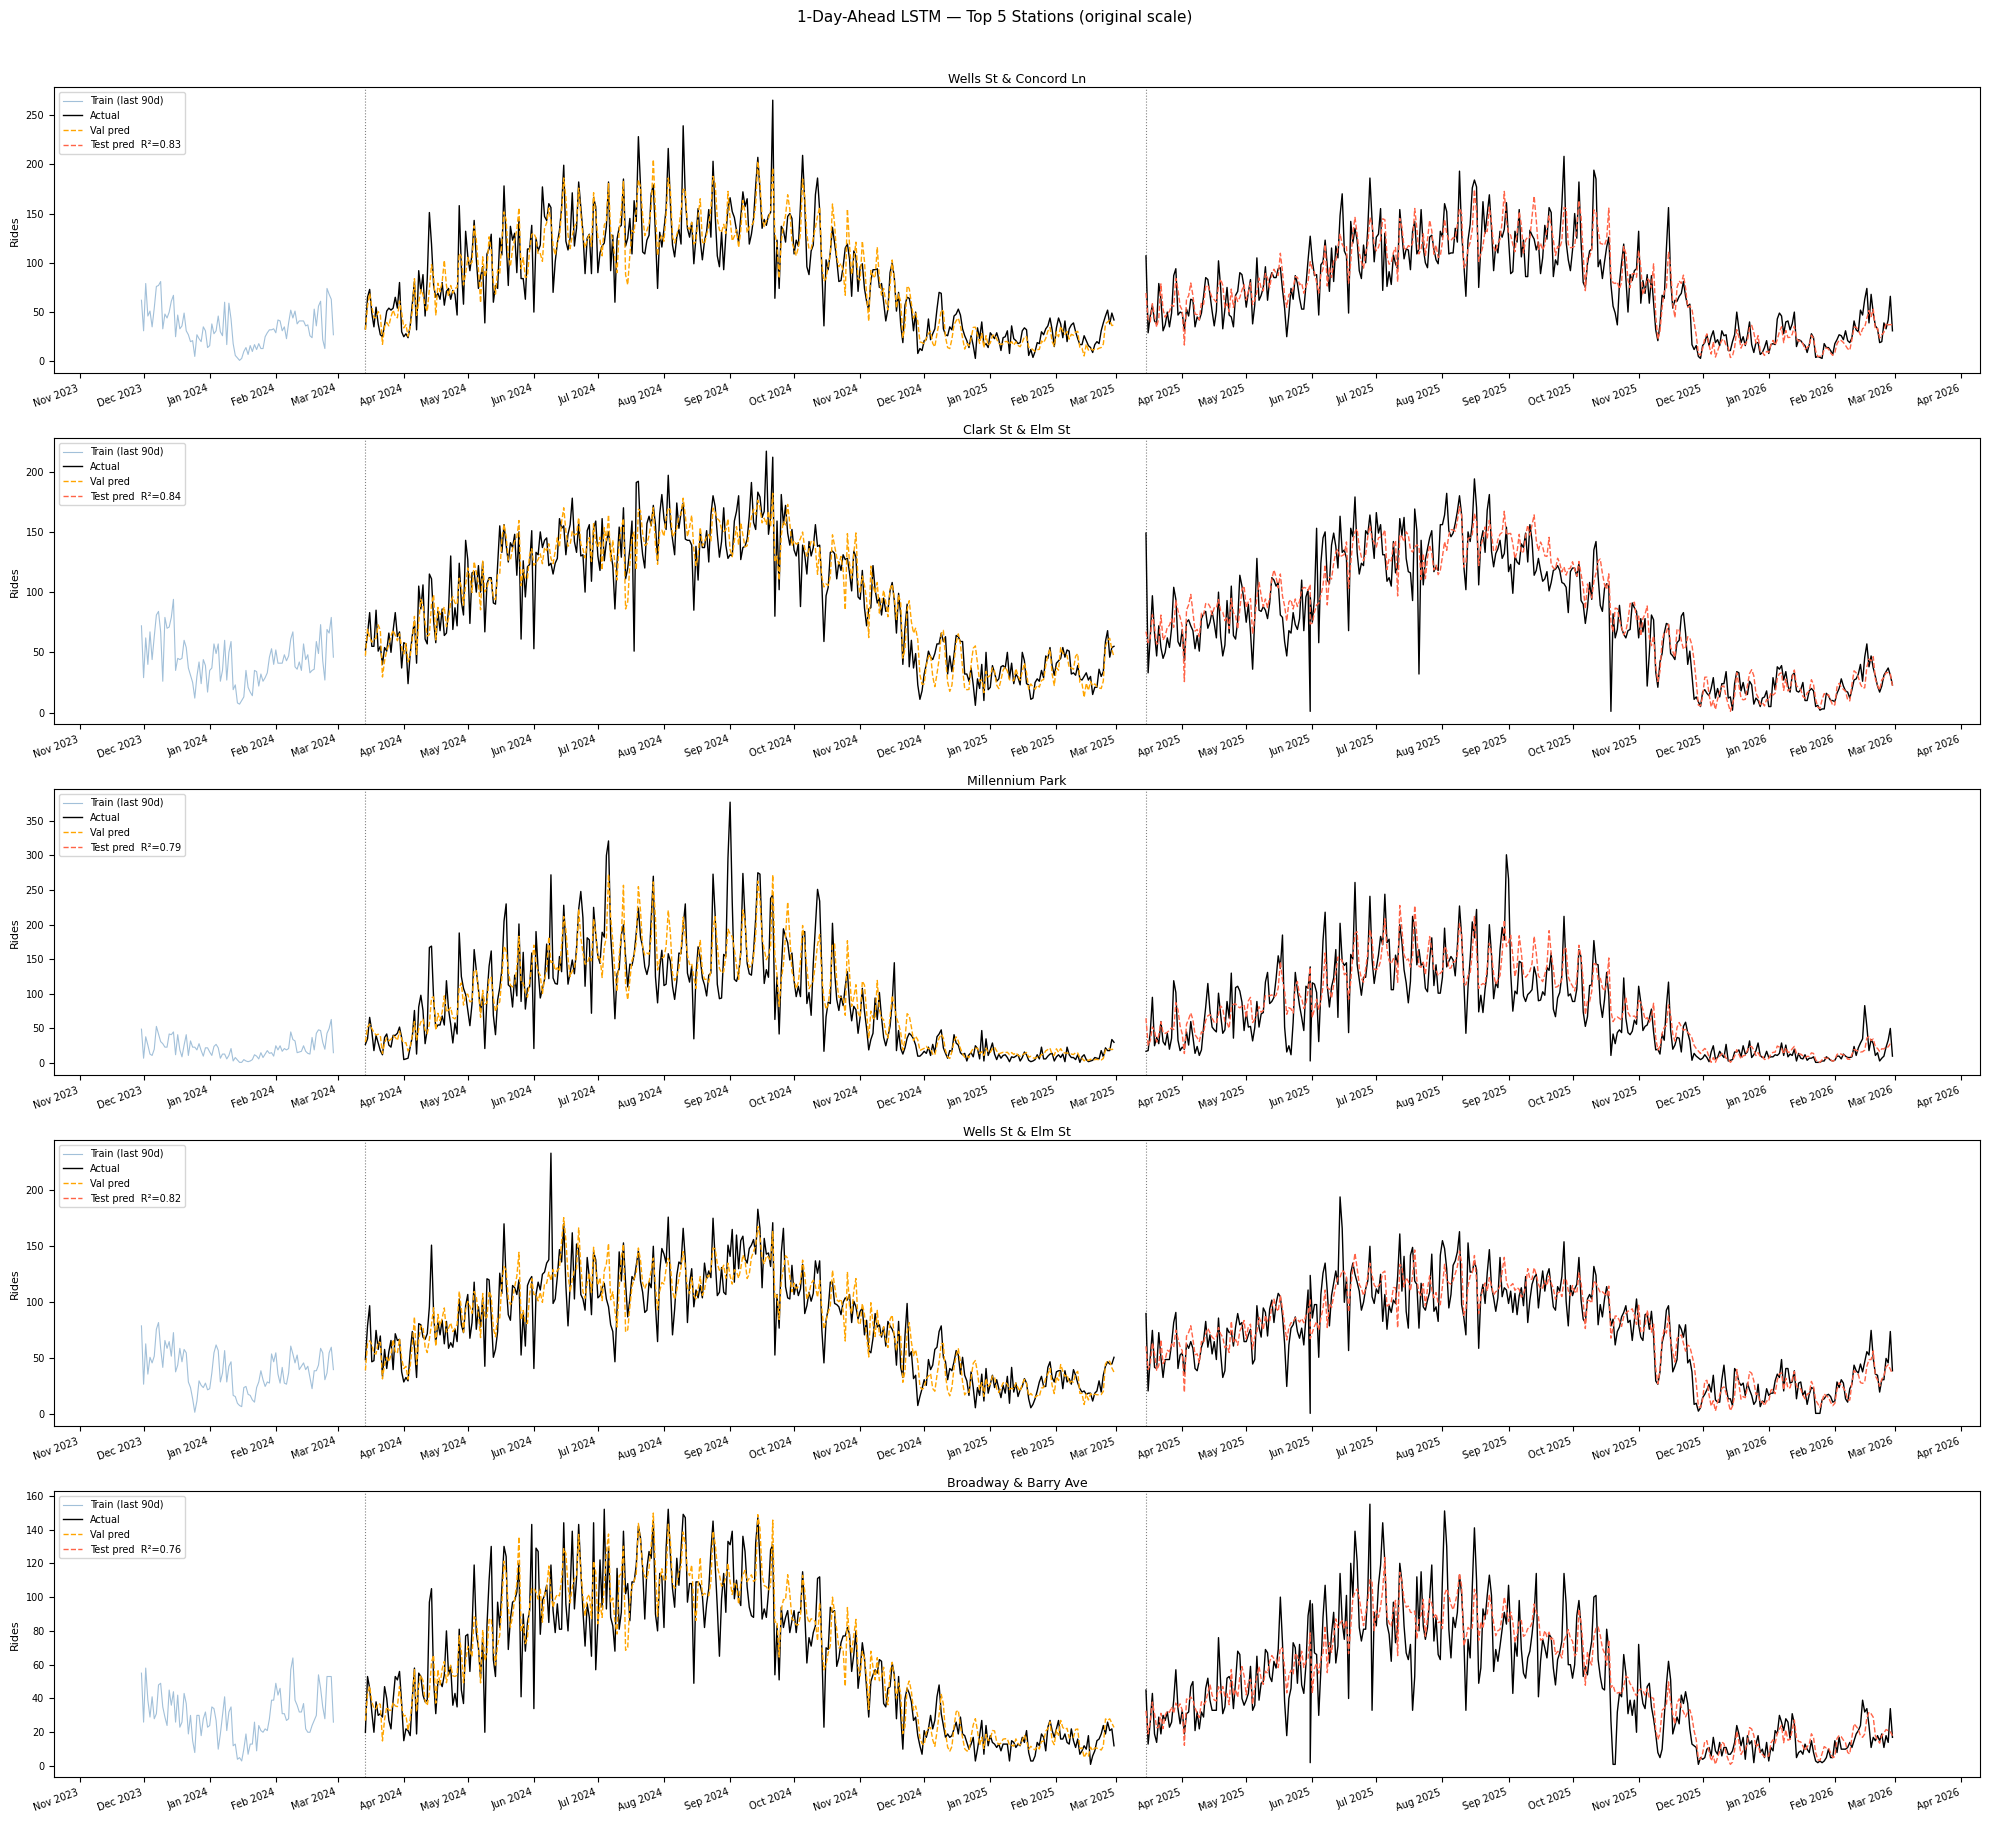

In [244]:
# Top 5 stations by total rides in train
top5 = (
    train.groupby("start_station_name")["total_rides"]
    .sum().sort_values(ascending=False).head(5).index.tolist()
)

CONTEXT_DAYS = 90
fig, axes = plt.subplots(5, 1, figsize=(20, 18), sharex=False)

for ax, name in zip(axes, top5):
    tr     = train[train["start_station_name"] == name].sort_values("date")
    tr_ctx = tr[tr["date"] >= tr["date"].max() - pd.Timedelta(days=CONTEXT_DAYS)]
    vl     = val_eval[val_eval["start_station_name"] == name].sort_values("date")
    te     = test_eval[test_eval["start_station_name"] == name].sort_values("date")
    r2_s   = per_station.loc[name, "r2"] if name in per_station.index else float("nan")

    ax.plot(tr_ctx["date"], tr_ctx["total_rides"], color="steelblue", alpha=0.5, linewidth=0.8, label="Train (last 90d)")
    ax.axvline(vl["date"].min(), color="grey", linestyle=":", linewidth=0.8)
    ax.axvline(te["date"].min(), color="grey", linestyle=":", linewidth=0.8)
    ax.plot(vl["date"], vl["total_rides"], color="black",  linewidth=1, label="Actual")
    ax.plot(vl["date"], vl["pred"],        color="orange", linestyle="--", linewidth=1, label="Val pred")
    ax.plot(te["date"], te["total_rides"], color="black",  linewidth=1)
    ax.plot(te["date"], te["pred"],        color="tomato", linestyle="--", linewidth=1, label=f"Test pred  R²={r2_s:.2f}")
    ax.set_title(name, fontsize=9, pad=3)
    ax.set_ylabel("Rides", fontsize=8)
    ax.legend(fontsize=7, loc="upper left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha="right", fontsize=7)
    ax.tick_params(axis="y", labelsize=7)

fig.suptitle("1-Day-Ahead LSTM — Top 5 Stations (original scale)", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

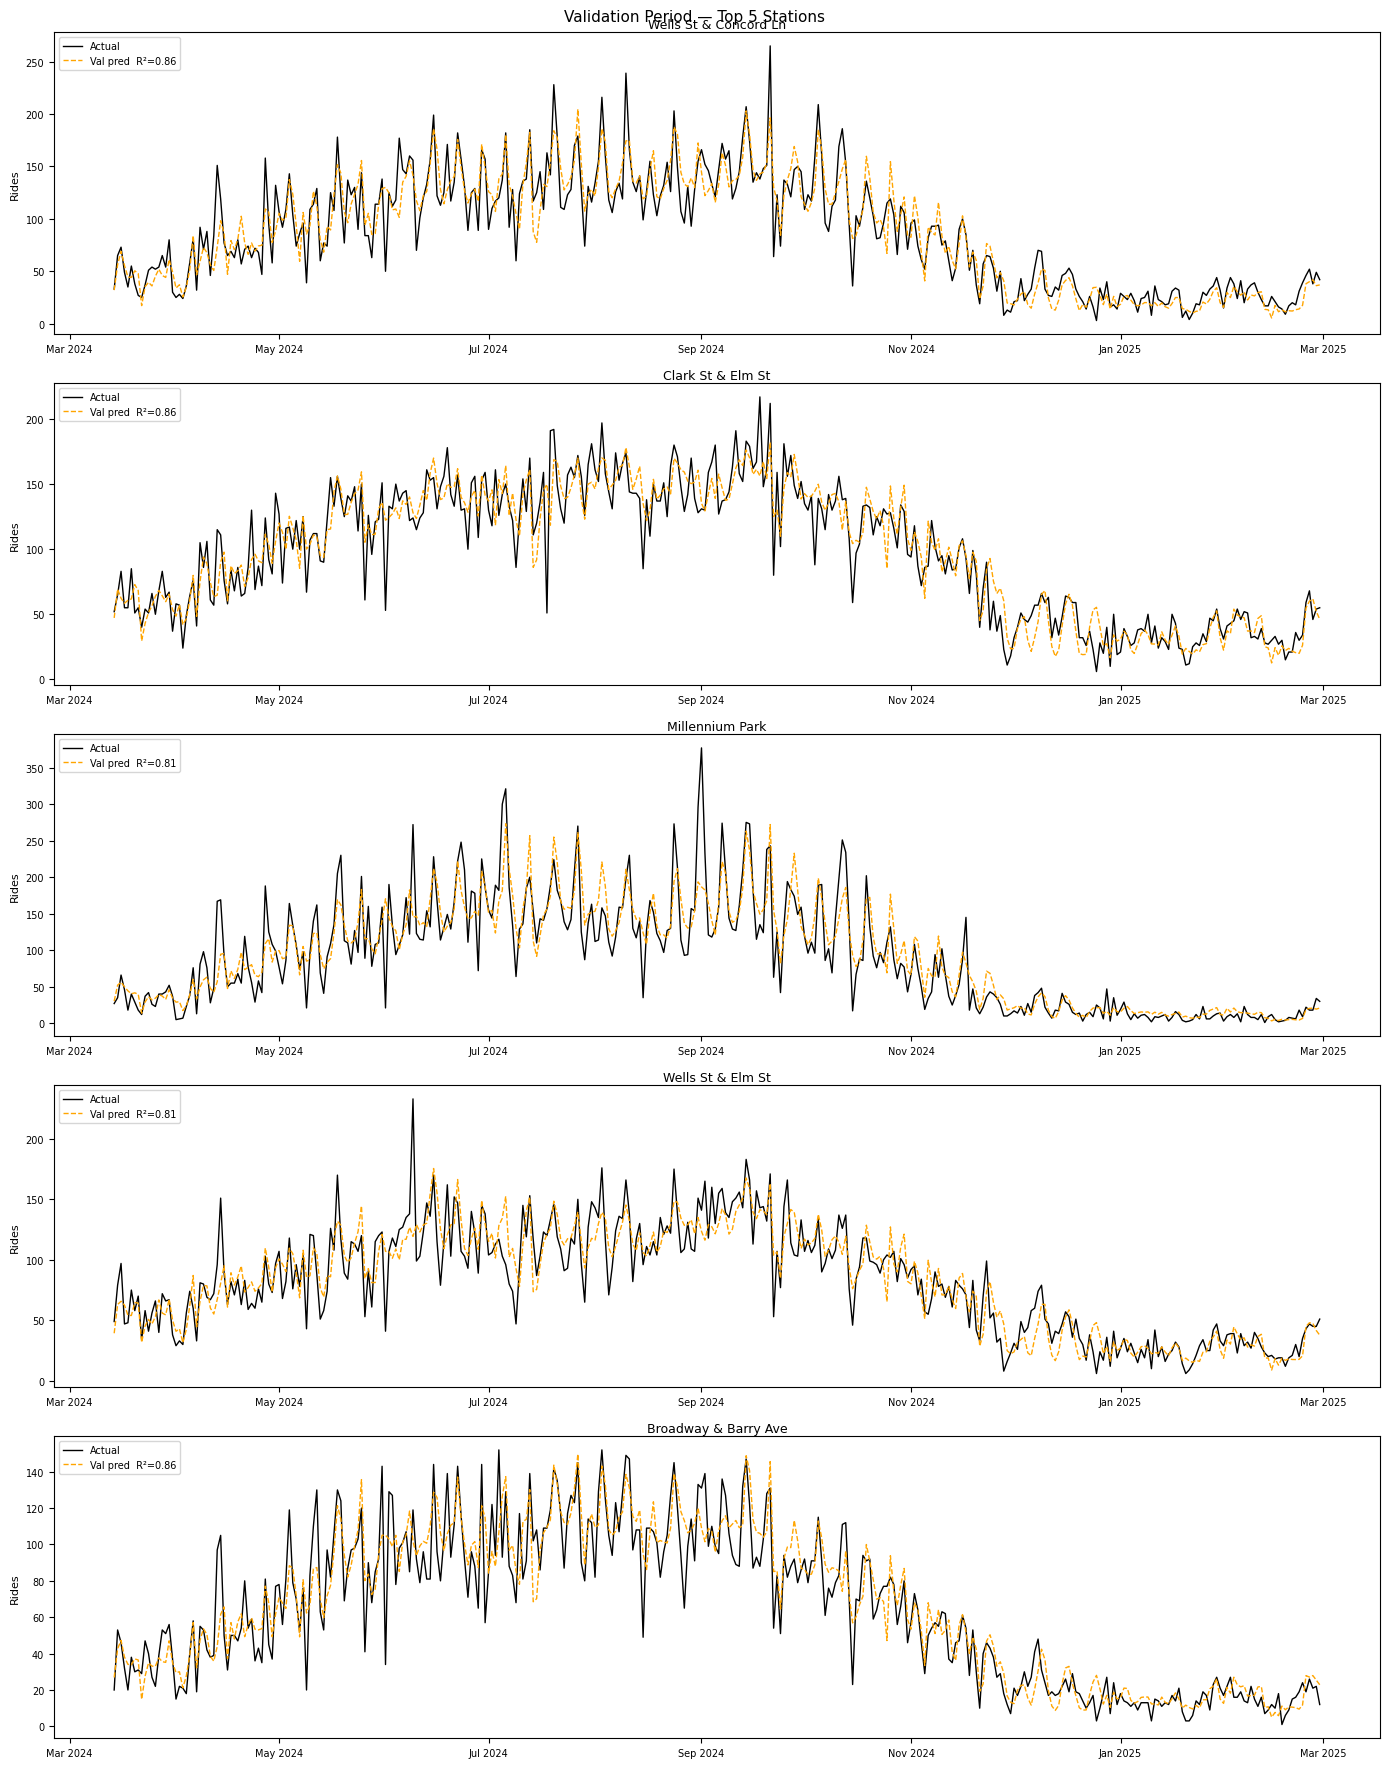

In [245]:
# Validation period only
fig, axes = plt.subplots(5, 1, figsize=(14, 18), sharex=False)

for ax, name in zip(axes, top5):
    vl   = val_eval[val_eval["start_station_name"] == name].sort_values("date")
    r2_v = r2_score(vl["total_rides"], vl["pred"])

    ax.plot(vl["date"], vl["total_rides"], color="black",  linewidth=1, label="Actual")
    ax.plot(vl["date"], vl["pred"],        color="orange", linestyle="--", linewidth=1, label=f"Val pred  R²={r2_v:.2f}")
    ax.set_title(name, fontsize=9, pad=3)
    ax.set_ylabel("Rides", fontsize=8)
    ax.legend(fontsize=7, loc="upper left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="both", labelsize=7)

fig.suptitle("Validation Period — Top 5 Stations", fontsize=11)
plt.tight_layout()
plt.show()

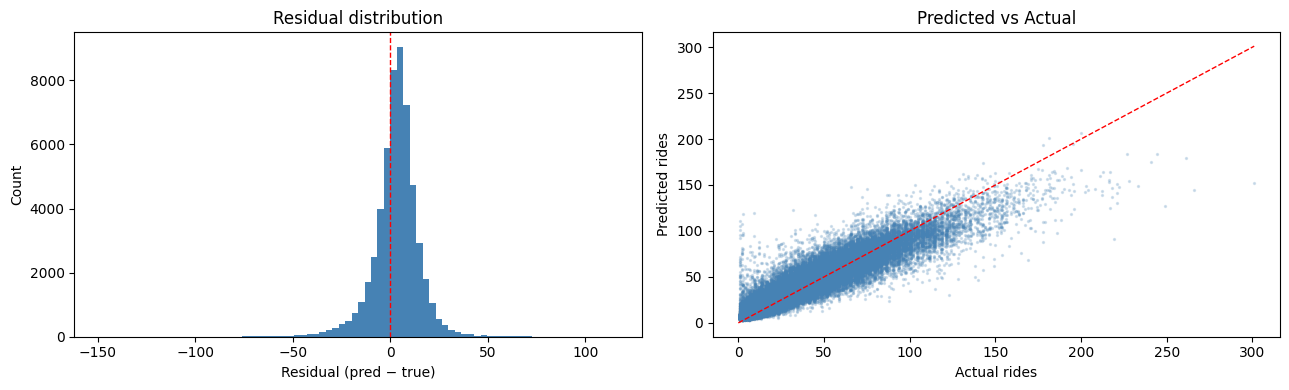

In [246]:
# Residual distribution
resid = y_pred - y_true
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(resid, bins=80, color='steelblue', edgecolor='none')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_xlabel('Residual (pred − true)')
axes[0].set_ylabel('Count')
axes[0].set_title('Residual distribution')

axes[1].scatter(y_true, y_pred, s=2, alpha=0.2, color='steelblue')
lim = max(y_true.max(), y_pred.max())
axes[1].plot([0, lim], [0, lim], 'r--', linewidth=1)
axes[1].set_xlabel('Actual rides')
axes[1].set_ylabel('Predicted rides')
axes[1].set_title('Predicted vs Actual')

plt.tight_layout()
plt.show()
